In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
import numpy as np
import sys
from hnn_core.utils import smooth_waveform


from hnn_tuning import NETWORK_SIM, HNN_CORE_MOD
neuron.load_mechanisms(str(HNN_CORE_MOD))
h.load_file("stdrun.hoc")
pathfig = str(NETWORK_SIM / 'figures' / 'conn')

from hnn_tuning.l5_plot_utils import get_l5pyr

plt.rcParams['pdf.fonttype'] = 'truetype'
plt.rcParams['pdf.fonttype'] = 42


Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


<Figure size 640x480 with 0 Axes>

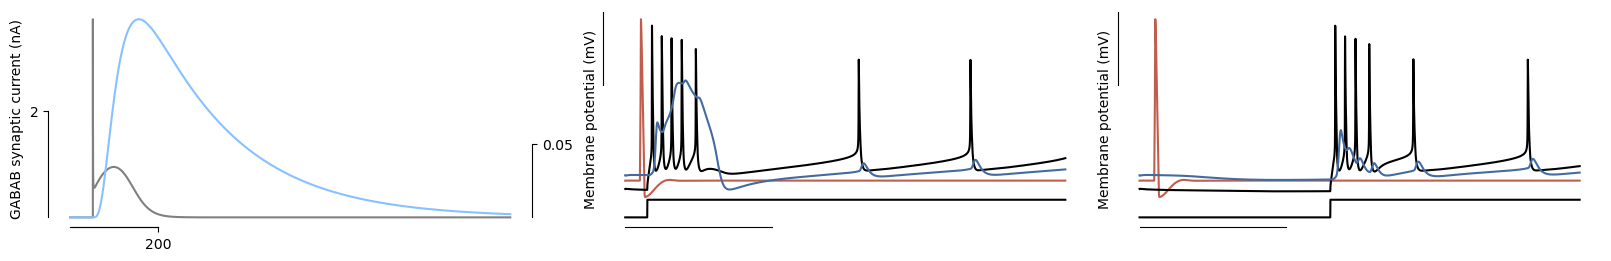

In [2]:
fig = plt.figure()
from matplotlib.gridspec import GridSpec


fig, ax = plt.subplots(1, 3, figsize=(16, 2.5), constrained_layout=True)
ax = ax.flatten()
l5pyr = get_l5pyr(add_syn='Exp2Syn', syn_loc='apical_tuft')
l5pyr.syn.e = -80
l5pyr.syn.tau1 = 1
l5pyr.syn.tau2 = 20

soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
nc.weight[0] = .35*12
nc.delay = 1

stim = h.IClamp(soma(0.5))
stim.delay = 50
stim.dur = 2    
stim.amp = 0.5

t = h.Vector().record(h._ref_t)
gababcurr = h.Vector().record(l5pyr.syn._ref_i)

h.finitialize()
h.continuerun(1000)

# old gabab
ax[0].plot(t, gababcurr, color='gray')
ax[0].set_ylabel('GABAB synaptic current (nA)')


l5pyr = get_l5pyr(add_syn='gabab_destexhe', syn_loc='apical_tuft')

soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
nc.weight[0] = .35*12
nc.delay = 1

stim = h.IClamp(soma(0.5))
stim.delay = 50
stim.dur = 2    
stim.amp = 0.5

t = h.Vector().record(h._ref_t)

gababcurr = h.Vector().record(l5pyr.syn._ref_i)

h.finitialize()
h.continuerun(1000)

# new gabab
ax0tw = ax[0].twinx()
ax0tw.plot(t, gababcurr, color='#87C1FF', label='new gabab')


ax[0].spines['left'].set_bounds([0, 2])
ax[0].spines['bottom'].set_bounds([0, 200])
ax[0].set_xticks([200])
ax[0].set_yticks([2])
ax[0].spines['top'].set_visible(False)
ax0tw.spines['right'].set_bounds([0, 0.05])
ax0tw.spines['bottom'].set_bounds([0, 200])
ax0tw.set_xticks([200])
ax0tw.set_yticks([0.05])
ax0tw.spines['top'].set_visible(False)
ax0tw.spines['left'].set_visible(False)

# new gabab immediately before Ca spike
l5pyr = get_l5pyr(add_syn='gabab_destexhe', syn_loc='apical_tuft')

soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
nc.weight[0] = .4*10
nc.delay = 1

stim = h.IClamp(soma(0.5))
stim.delay = 10
stim.dur = 2    
stim.amp = 0.5

l5stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
l5stim.delay = 15
l5stim.dur = 300
l5stim.amp = 3
clamp_current = h.Vector().record(l5stim._ref_i)

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma(0.5)._ref_v)
v_post_apical = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
gababcurr = h.Vector().record(l5pyr.syn._ref_i)

h.finitialize()
h.continuerun(300)

ax[1].plot(t, v_pre, color='#c05d4d', label='pre soma')
ax[1].plot(t, v_post_soma, color='k', label='post soma')
ax[1].plot(t, v_post_apical, color='#446b9f', label='post apical')
ax[1].plot(t, clamp_current*4-90, color='k')

ax[1].set_ylabel('Membrane potential (mV)')

# new gabab calcium spike delay
l5pyr = get_l5pyr(add_syn='gabab_destexhe', syn_loc='apical_tuft')

soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
nc.weight[0] = .4*10
nc.delay = 1

stim = h.IClamp(soma(0.5))
stim.delay = 10
stim.dur = 2    
stim.amp = 0.5

l5stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
l5stim.delay = 130
l5stim.dur = 300
l5stim.amp = 3
clamp_current = h.Vector().record(l5stim._ref_i)


t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma(0.5)._ref_v)
v_post_apical = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
gababcurr = h.Vector().record(l5pyr.syn._ref_i)

h.finitialize()
h.continuerun(300)

# ax[3].plot(t, gababcurr, color='#97C1E6')
# ax[4].set_ylabel('GABAB synaptic current (nA)')

ax[2].plot(t, v_pre, color='#c05d4d', label='pre soma')
ax[2].plot(t, v_post_soma, color='k', label='post soma')
ax[2].plot(t, v_post_apical, color='#446b9f', label='post apical')
ax[2].plot(t, clamp_current*4-90, color='k')

ax[2].set_ylabel('Membrane potential (mV)')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

for a in ax[1:]:
    a.spines['left'].set_bounds([0, 50])
    a.spines['bottom'].set_bounds([0, 100])
    a.set_xticks([])
    a.set_yticks([])

fig.savefig(f'{pathfig}/gabab_new_vs_old.png')
fig.savefig(f'{pathfig}/gabab_new_vs_old.pdf')

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Adding multiple synapses to cell.


<Figure size 640x480 with 0 Axes>

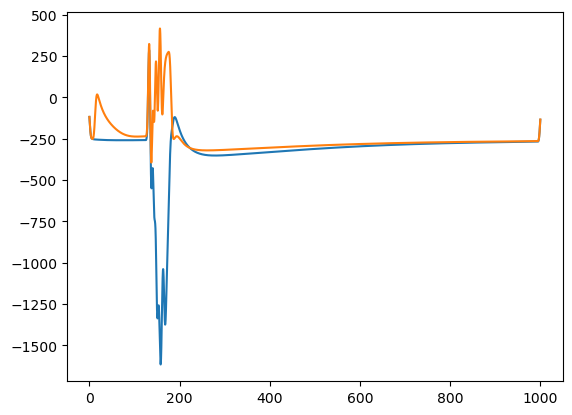

In [3]:
fig = plt.figure()
from matplotlib.gridspec import GridSpec


fig, ax = plt.subplots()

# new gabab immediately before Ca spike
l5pyr = get_l5pyr(add_syn='gabab_destexhe', syn_loc='apical_tuft')

l5stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
l5stim.delay = 130
l5stim.dur = 50
l5stim.amp = 3
clamp_current = h.Vector().record(l5stim._ref_i)

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma(0.5)._ref_v)
v_post_apical = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
gababcurr = h.Vector().record(l5pyr.syn._ref_i)

h.finitialize()
h.continuerun(1000)


dpl_smooth = smooth_waveform(l5pyr.dipole.as_numpy(), 10, 1000/h.dt)

ax.plot(t, dpl_smooth)

# new gabab calcium spike delay
l5pyr = get_l5pyr(add_syn=['gabab_destexhe', 'gabaa_som+'], syn_loc='apical_tuft')

soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc1 = h.NetCon(soma(0.5)._ref_v, l5pyr.syn[0], sec=soma)
nc1.weight[0] = .4*10
nc1.delay = 1

nc2 = h.NetCon(soma(0.5)._ref_v, l5pyr.syn[1], sec=soma)
nc2.weight[0] = .4
nc2.delay = 1

stim = h.IClamp(soma(0.5))
stim.delay = 10
stim.dur = 2    
stim.amp = 0.5

l5stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
l5stim.delay = 130
l5stim.dur = 50
l5stim.amp = 3
clamp_current = h.Vector().record(l5stim._ref_i)


t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma(0.5)._ref_v)
v_post_apical = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.finitialize()
h.continuerun(1000)

# ax[3].plot(t, gababcurr, color='#97C1E6')
# ax[4].set_ylabel('GABAB synaptic current (nA)')
dpl_smooth_gabab = smooth_waveform(l5pyr.dipole.as_numpy(), 10, 1000/h.dt)

ax.plot(t, dpl_smooth_gabab)




In [4]:
# some weird alpha questions related stuff to try out

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Adding multiple synapses to cell.


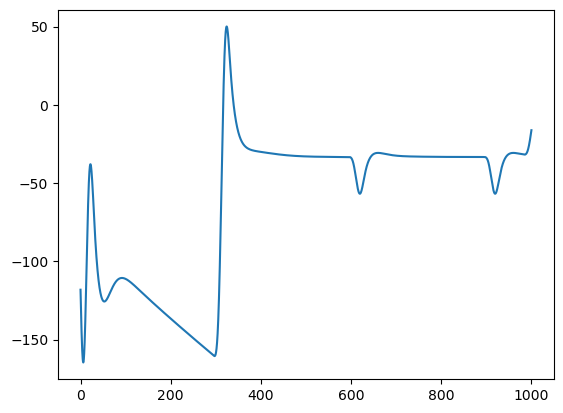

In [14]:
l5pyr = get_l5pyr(add_syn=['gabab_destexhe', 'gabaa_som+'], syn_loc='apical_tuft')

soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc1 = h.NetCon(soma(0.5)._ref_v, l5pyr.syn[0], sec=soma)
nc1.weight[0] = .4*20
nc1.delay = 1

nc2 = h.NetCon(soma(0.5)._ref_v, l5pyr.syn[1], sec=soma)
nc2.weight[0] = .4
nc2.delay = 1

stim = [None]*5

for idx_s, s in enumerate(stim):
    stim[idx_s] = h.IClamp(soma(0.5))
    stim[idx_s].delay = 10+idx_s*300
    stim[idx_s].dur = 2    
    stim[idx_s].amp = 0.5

# l5stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
# l5stim.delay = 100
# l5stim.dur = 800
# l5stim.amp = 3
# clamp_current = h.Vector().record(l5stim._ref_i)


t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma(0.5)._ref_v)
v_post_apical = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.finitialize()
h.continuerun(1000)

# ax[3].plot(t, gababcurr, color='#97C1E6')
# ax[4].set_ylabel('GABAB synaptic current (nA)')
dpl_smooth_gabab = smooth_waveform(l5pyr.dipole.as_numpy(), 30, 1000/h.dt)

plt.plot(t, dpl_smooth_gabab)

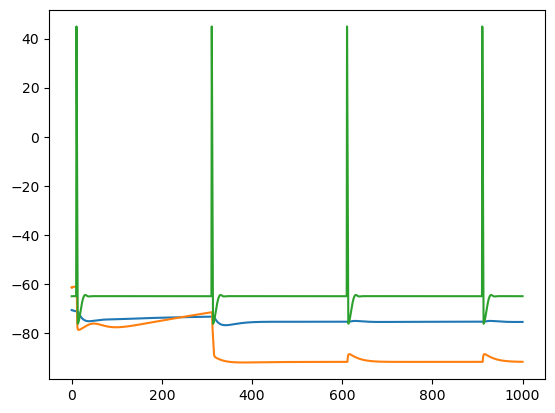

In [15]:
plt.plot(t, v_post_soma)
plt.plot(t, v_post_apical)
plt.plot(t, v_pre)

In [16]:
from scipy.signal import welch

f, welch_dipole = welch(dpl_smooth_gabab, fs = 1000/h.dt, window='hann', nperseg=1024)

(0.0, 100.0)

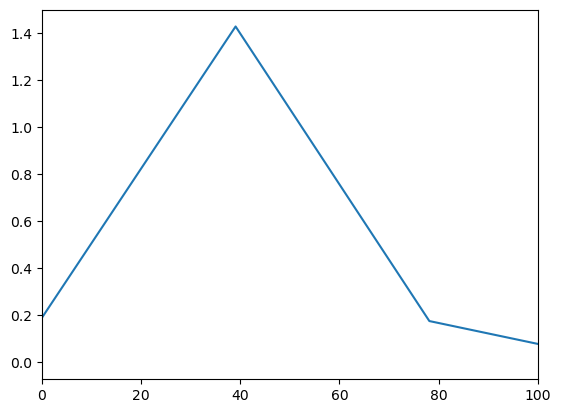

In [17]:
plt.plot(f, welch_dipole)
plt.xlim([0,100])